In [1]:
# Import Package
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from scipy.stats import normaltest, chi2_contingency, mannwhitneyu, ttest_ind
import folium
from folium.plugins import MarkerCluster
from geopy.distance import geodesic
from sklearn.preprocessing import LabelEncoder
import math
import scipy.stats as stats
from scipy.stats import fisher_exact
from scipy.stats import ttest_rel

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Read Data
df = pd.read_csv("accident_data.csv")

In [3]:
# Data Understanding
display (df.head())

,Index,Accident_Severity,Accident Date,Latitude,Light_Conditions,District Area,Longitude,Number_of_Casualties,Number_of_Vehicles,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200701BS64157,Serious,05-06-2019,51.506187,Darkness - lights lit,Kensington and Chelsea,-0.209082,1,2,Dry,Single carriageway,Urban,Fine no high winds,Car
1,200701BS65737,Serious,02-07-2019,51.495029,Daylight,Kensington and Chelsea,-0.173647,1,2,Wet or damp,Single carriageway,Urban,Raining no high winds,Car
2,200701BS66127,Serious,26-08-2019,51.517715,Darkness - lighting unknown,Kensington and Chelsea,-0.210215,1,3,Dry,NaN,Urban,NaN,Taxi/Private hire car
3,200701BS66128,Serious,16-08-2019,51.495478,Daylight,Kensington and Chelsea,-0.202731,1,4,Dry,Single carriageway,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
4,200701BS66837,Slight,03-09-2019,51.488576,Darkness - lights lit,Kensington and Chelsea,-0.192487,1,2,Dry,NaN,Urban,NaN,Other vehicle


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 670679 entries, 0 to 670678
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Index                    670679 non-null  object 
 1   Accident_Severity        670679 non-null  object 
 2   Accident Date            670679 non-null  object 
 3   Latitude                 670654 non-null  float64
 4   Light_Conditions         670679 non-null  object 
 5   District Area            670679 non-null  object 
 6   Longitude                670653 non-null  float64
 7   Number_of_Casualties     670679 non-null  int64  
 8   Number_of_Vehicles       670679 non-null  int64  
 9   Road_Surface_Conditions  669937 non-null  object 
 10  Road_Type                666099 non-null  object 
 11  Urban_or_Rural_Area      670664 non-null  object 
 12  Weather_Conditions       656328 non-null  object 
 13  Vehicle_Type             670679 non-null  object 
dtypes: f

In [5]:
df_unique = []

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)

for i in df.columns:
    unique_count = df[i].nunique()
    unique_values = df[i].unique()
    data_type = df[i].dtype
    df_unique.append({
        "Column Name": i,
        "Number of Unique": unique_count,
        "Data Type": data_type,
        "Unique Sample": unique_values
    })

df_unique = pd.DataFrame(df_unique)
display(df_unique)

,Column Name,Number of Unique,Data Type,Unique Sample
0,Index,431020,object,"[200701BS64157, 200701BS65737, 200701BS66127, 200701BS66128, 200701BS66837, 200701BS67159, 200701BS67207, 200701BS67370, 200701BS67515, 200701BS67543, 200701BS67644, 200701BS67747, 200701BS67773, 200701BS67853, 200701BS67859, 200701BS67960, 200701BS67969, 200701BS68160, 200701BS68210, 200701BS68237, 200701BS68301, 200701BS68302, 200701BS70001, 200701BS70002, 200701BS70003, 200701BS70004, 200701BS70005, 200701BS70006, 200701BS70007, 200701BS70008, 200701BS70009, 200701BS70010, 200701BS70011, 200701BS70012, 200701BS70013, 200701BS70014, 200701BS70015, 200701BS70016, 200701BS70017, 200701BS70019, 200701BS70020, 200701BS70021, 200701BS70022, 200701BS70023, 200701BS70024, 200701BS70025, 200701BS70026, 200701BS70028, 200701BS70029, 200701BS70032, 200701BS70034, 200701BS70035, 200701BS70036, 200701BS70037, 200701BS70038, 200701BS70039, 200701BS70040, 200701BS70041, 200701BS70042, 200701BS70043, 200701BS70044, 200701BS70045, 200701BS70046, 200701BS70047, 200701BS70049, 200701BS70050, 200701BS70051, 200701BS70052, 200701BS70053, 200701BS70054, 200701BS70055, 200701BS70057, 200701BS70058, 200701BS70059, 200701BS70060, 200701BS70061, 200701BS70062, 200701BS70063, 200701BS70064, 200701BS70065, 200701BS70066, 200701BS70067, 200701BS70068, 200701BS70069, 200701BS70070, 200701BS70071, 200701BS70072, 200701BS70073, 200701BS70074, 200701BS70075, 200701BS70076, 200701BS70077, 200701BS70079, 200701BS70080, 200701BS70081, 200701BS70082, 200701BS70083, 200701BS70084, 200701BS70085, 200701BS70086, ...]"
1,Accident_Severity,3,object,"[Serious, Slight, Fatal]"
2,Accident Date,2556,object,"[05-06-2019, 02-07-2019, 26-08-2019, 16-08-2019, 03-09-2019, 18-09-2019, 05-09-2019, 03-10-2019, 31-10-2019, 18-10-2019, 09-10-2019, 02-11-2019, 12-11-2019, 08-11-2019, 01-11-2019, 19-11-2019, 01-10-2019, 10-10-2019, 20-11-2019, 26-11-2019, 24-10-2019, 24-11-2019, 18-01-2019, 22-01-2019, 17-01-2019, 03-01-2019, 02-01-2019, 06-01-2019, 12-01-2019, 09-01-2019, 13-01-2019, 07-01-2019, 08-01-2019, 10-01-2019, 16-01-2019, 15-01-2019, 14-01-2019, 04-01-2019, 20-01-2019, 26-01-2019, 28-01-2019, 24-01-2019, 27-01-2019, 25-01-2019, 08-02-2019, 10-02-2019, 06-02-2019, 04-02-2019, 01-02-2019, 31-01-2019, 30-01-2019, 03-02-2019, 05-02-2019, 14-02-2019, 12-02-2019, 07-02-2019, 13-02-2019, 19-02-2019, 16-02-2019, 22-02-2019, 11-02-2019, 28-02-2019, 25-02-2019, 18-02-2019, 27-02-2019, 24-02-2019, 03-03-2019, 02-03-2019, 05-03-2019, 01-03-2019, 06-03-2019, 13-03-2019, 20-03-2019, 10-03-2019, 14-03-2019, 21-03-2019, 08-03-2019, 16-03-2019, 15-03-2019, 17-03-2019, 18-03-2019, 25-03-2019, 11-03-2019, 26-03-2019, 23-03-2019, 22-03-2019, 24-03-2019, 30-03-2019, 28-03-2019, 29-03-2019, 02-02-2019, 03-04-2019, 02-04-2019, 15-04-2019, 08-04-2019, 16-04-2019, 13-04-2019, 04-04-2019, 21-04-2019, 12-04-2019, ...]"
3,Latitude,519907,float64,"[51.506187, 51.495029, 51.517715, 51.495478, 51.488576, 51.49775, 51.501405, 51.48226, 51.493319, 51.484539, 51.491944, 51.499127, 51.500823, 51.508999, 51.485125, 51.49349, 51.508445, 51.49759, 51.482988, 51.505996, 51.486795, 51.499983, 51.485674, 51.498157, 51.493311, 51.49806, 51.490526, 51.513352, 51.514951, 51.514489, 51.480325, 51.494902, 51.514399, 51.498244, 51.524885, 51.497451, 51.492577, 51.508535, 51.493766, 51.48943, 51.493753, 51.481746, 51.49721, 51.485216, 51.485589, 51.488489, 51.485849, 51.481152, 51.492624, 51.49859, 51.527693, 51.482775, 51.491908, 51.510711, 51.500933, 51.497725, 51.48849, 51.491499, 51.528344, 51.480261, 51.489416, 51.4996, 51.494905, 51.492622, 51.503223, 51.497541, 51.511079, 51.458413, 51.50689, 51.487655, 51.506014, 51.480458, 51.493503, 51.484449, 51.491742, 51.490715, 51.498204, 51.486026, 51.510897, 51.501428, 51.494612, 51.493914, 51.522561, 51.518081, 51.490546, 51.482076, 51.482637, 51.48757, 51.496411, 51.500497, 51.495191, 51.5159, 51.480177, 51.50768, 51.487141, 51.496464, 51.485757, 51.48342, 51.518935, 51.49566, ...]"
4,Light_

In [6]:
pd.reset_option("all")

def df_null_summary():
    global null_summary

    null_counts = df.isna().sum()
    null_percentages = (null_counts / len(df)) * 100
    null_summary = pd.DataFrame({
        'Null Count': null_counts,
        'Null Percentage': round(null_percentages, 3)
    })

    return null_summary


df_null_summary()

,Null Count,Null Percentage
Index,0,0.000
Accident_Severity,0,0.000
Accident Date,0,0.000
Latitude,25,0.004
Light_Conditions,0,0.000
District Area,0,0.000
Longitude,26,0.004
Number_of_Casualties,0,0.000
Number_of_Vehicles,0,0.000
Road_Surface_Conditions,742,0.111


In [7]:
# Display only the features that contain missing values
missing_only = null_summary[null_summary['Null Count'] > 0]
display(missing_only)

,Null Count,Null Percentage
Latitude,25,0.004
Longitude,26,0.004
Road_Surface_Conditions,742,0.111
Road_Type,4580,0.683
Urban_or_Rural_Area,15,0.002
Weather_Conditions,14351,2.140


In [8]:
# Total missing values
total_missing = df.isna().sum().sum()

# Total values in the DataFrame
total_values = df.size

# Percentage of missing values
missing_percentage = (total_missing / total_values) * 100

print(f"Percentage of missing values: {missing_percentage:.2f}%")

Percentage of missing values: 0.21%


<Axes: >

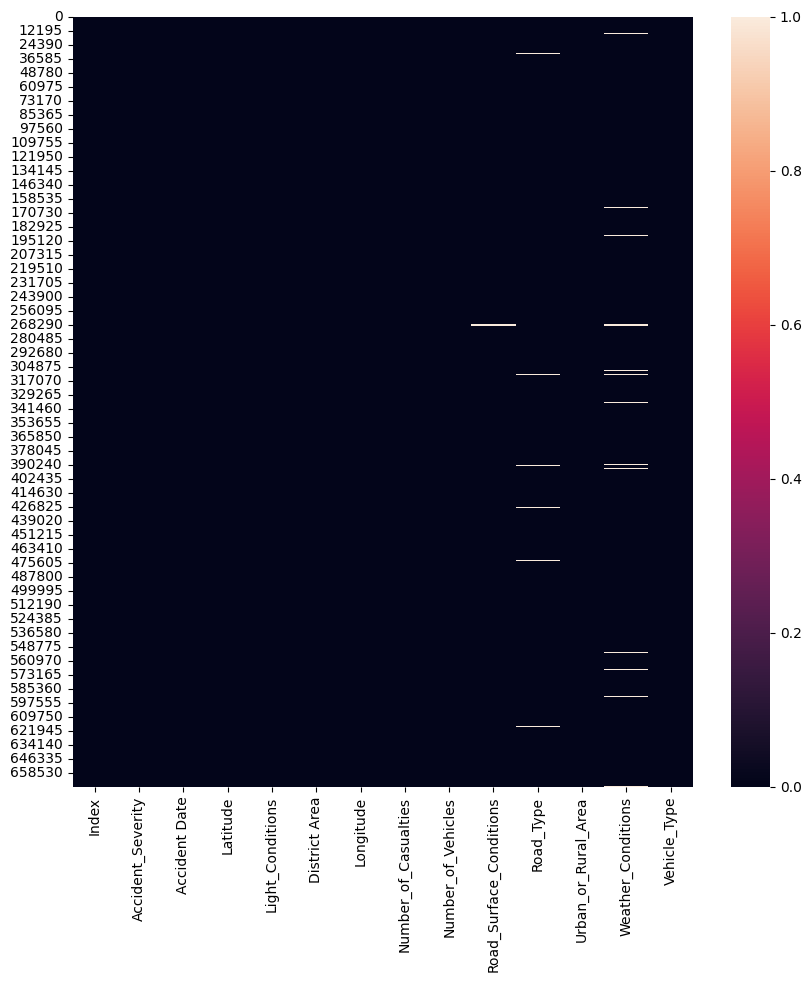

In [9]:
#Data Cleaning
#Asign Nas
plt.figure(figsize=(10,10))
sns.heatmap(df.isna())


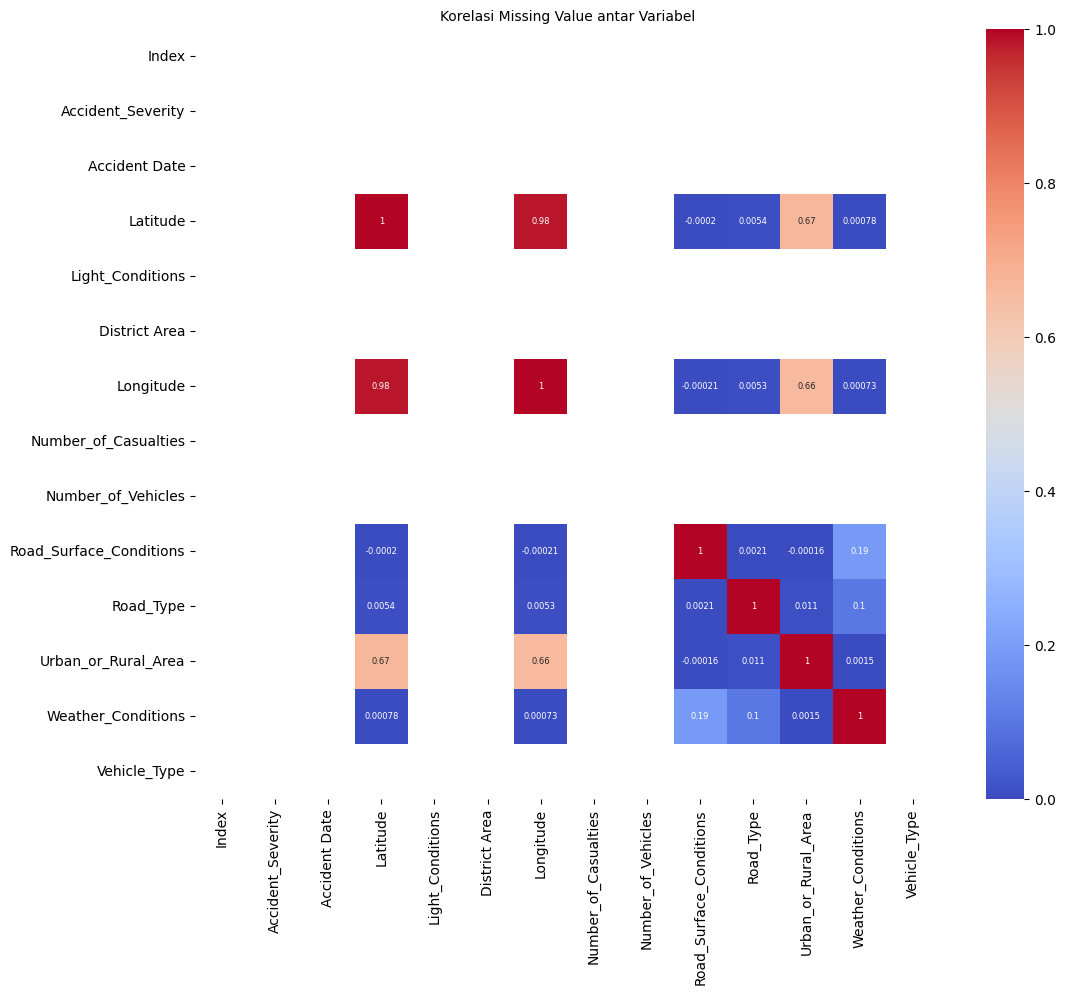

It was found that there is no strong correlation between the road type and weather conditions columns


In [10]:
missing_corr = df.isnull().corr()
plt.figure(figsize=(12, 10))
sns.heatmap(missing_corr, annot=True, cmap='coolwarm', annot_kws={'size': 6})
plt.title("Korelasi Missing Value antar Variabel", fontsize=10)
plt.show()
print ('It was found that there is no strong correlation between the road type and weather conditions columns')

It was found that there is no strong correlation between the road type and weather conditions columns


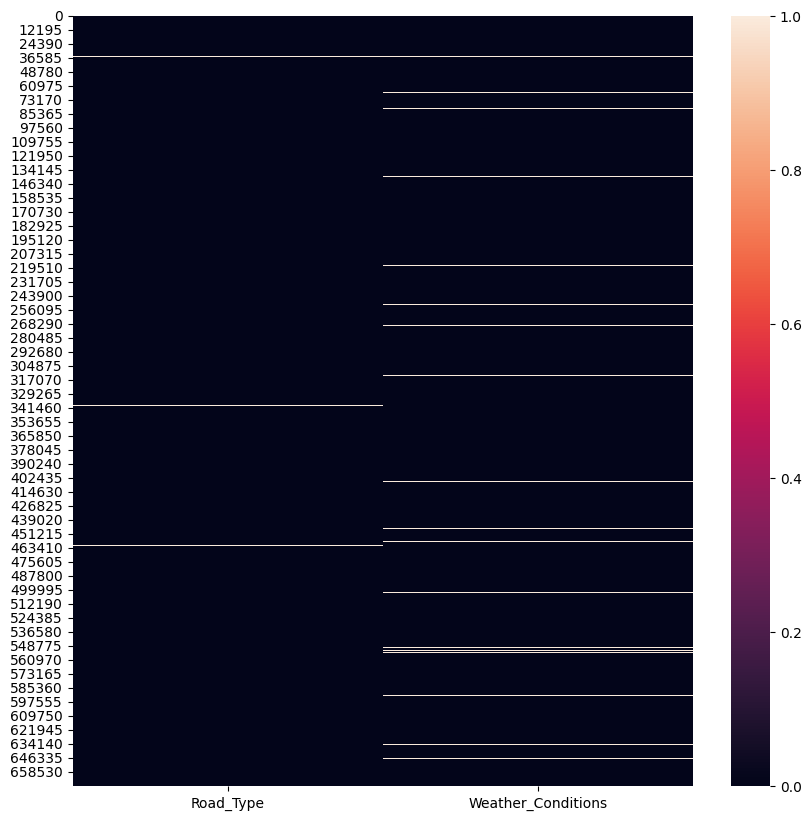

In [11]:
# Road_Type and Weather_Conditions
plt.figure(figsize=(10,10))
sns.heatmap(df[["Road_Type","Weather_Conditions"]].isna())
print ('It was found that there is no strong correlation between the road type and weather conditions columns')

In [12]:
# Mengisi nilai yang kosong dengan "Unknown"
df = df.fillna("Unknown")

# Memeriksa kembali ringkasan missing value setelah pengisian
print("Jumlah nilai null setelah dibersihkan:")
print(df.isna().sum())

# Menampilkan sampel data hasil pembersihan
display(df.head())

Jumlah nilai null setelah dibersihkan:
Index                      0
Accident_Severity          0
Accident Date              0
Latitude                   0
Light_Conditions           0
District Area              0
Longitude                  0
Number_of_Casualties       0
Number_of_Vehicles         0
Road_Surface_Conditions    0
Road_Type                  0
Urban_or_Rural_Area        0
Weather_Conditions         0
Vehicle_Type               0
dtype: int64


,Index,Accident_Severity,Accident Date,Latitude,Light_Conditions,District Area,Longitude,Number_of_Casualties,Number_of_Vehicles,Road_Surface_Conditions,Road_Type,Urban_or_Rural_Area,Weather_Conditions,Vehicle_Type
0,200701BS64157,Serious,05-06-2019,51.506187,Darkness - lights lit,Kensington and Chelsea,-0.209082,1,2,Dry,Single carriageway,Urban,Fine no high winds,Car
1,200701BS65737,Serious,02-07-2019,51.495029,Daylight,Kensington and Chelsea,-0.173647,1,2,Wet or damp,Single carriageway,Urban,Raining no high winds,Car
2,200701BS66127,Serious,26-08-2019,51.517715,Darkness - lighting unknown,Kensington and Chelsea,-0.210215,1,3,Dry,Unknown,Urban,Unknown,Taxi/Private hire car
3,200701BS66128,Serious,16-08-2019,51.495478,Daylight,Kensington and Chelsea,-0.202731,1,4,Dry,Single carriageway,Urban,Fine no high winds,Bus or coach (17 or more pass seats)
4,200701BS66837,Slight,03-09-2019,51.488576,Darkness - lights lit,Kensington and Chelsea,-0.192487,1,2,Dry,Unknown,Urban,Unknown,Other vehicle


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 670679 entries, 0 to 670678
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype 
---  ------                   --------------   ----- 
 0   Index                    670679 non-null  object
 1   Accident_Severity        670679 non-null  object
 2   Accident Date            670679 non-null  object
 3   Latitude                 670679 non-null  object
 4   Light_Conditions         670679 non-null  object
 5   District Area            670679 non-null  object
 6   Longitude                670679 non-null  object
 7   Number_of_Casualties     670679 non-null  int64 
 8   Number_of_Vehicles       670679 non-null  int64 
 9   Road_Surface_Conditions  670679 non-null  object
 10  Road_Type                670679 non-null  object
 11  Urban_or_Rural_Area      670679 non-null  object
 12  Weather_Conditions       670679 non-null  object
 13  Vehicle_Type             670679 non-null  object
dtypes: int64(2), object(

### Keterangan Kolom Dataset

Berikut adalah penjelasan detail untuk setiap kolom yang terdapat di dalam dataset:

* **`Index`**: Nomor identifikasi unik atau nomor referensi untuk setiap catatan data kecelakaan.
* **`Accident_Severity`**: Tingkat keparahan kecelakaan (misalnya: *Serious* / berat, atau *Slight* / ringan).
* **`Accident Date`**: Tanggal terjadinya insiden kecelakaan lalu lintas (format: Hari-Bulan-Tahun).
* **`Latitude`**: Titik koordinat lintang geografis lokasi terjadinya kecelakaan (misalnya: `51.506187`).
* **`Light_Conditions`**: Kondisi pencahayaan saat kecelakaan terjadi (misalnya: *Daylight* / siang hari terang, atau *Darkness - lights lit* / malam hari dengan lampu penerangan jalan menyala).
* **`District Area`**: Nama wilayah atau distrik tempat kecelakaan berlangsung (contohnya: *Kensington and Chelsea*).
* **`Longitude`**: Titik koordinat bujur geografis lokasi kecelakaan (misalnya: `-0.209082`).
* **`Number_of_Casualties`**: Jumlah korban jiwa atau korban yang mengalami luka-luka akibat kecelakaan tersebut.
* **`Number_of_Vehicles`**: Jumlah kendaraan yang terlibat dalam insiden kecelakaan tersebut.
* **`Road_Surface_Conditions`**: Kondisi permukaan jalan saat kejadian (misalnya: *Dry* / kering, atau *Wet or damp* / basah/lembab).
* **`Road_Type`**: Jenis atau tipe jalan tempat kecelakaan terjadi (misalnya: *Single carriageway* / jalan satu jalur dua arah).
* **`Urban_or_Rural_Area`**: Klasifikasi apakah lokasi kejadian berada di kawasan perkotaan (*Urban*) atau pedesaan (*Rural*).
* **`Weather_Conditions`**: Kondisi cuaca saat kecelakaan terjadi (misalnya: *Fine no high winds* / cerah tidak berangin, atau *Raining no high winds* / hujan tanpa angin kencang).
* **`Vehicle_Type`**: Jenis kendaraan yang terlibat (misalnya: *Car* / mobil, *Taxi/Private hire car*, *Bus or coach*, dll.).

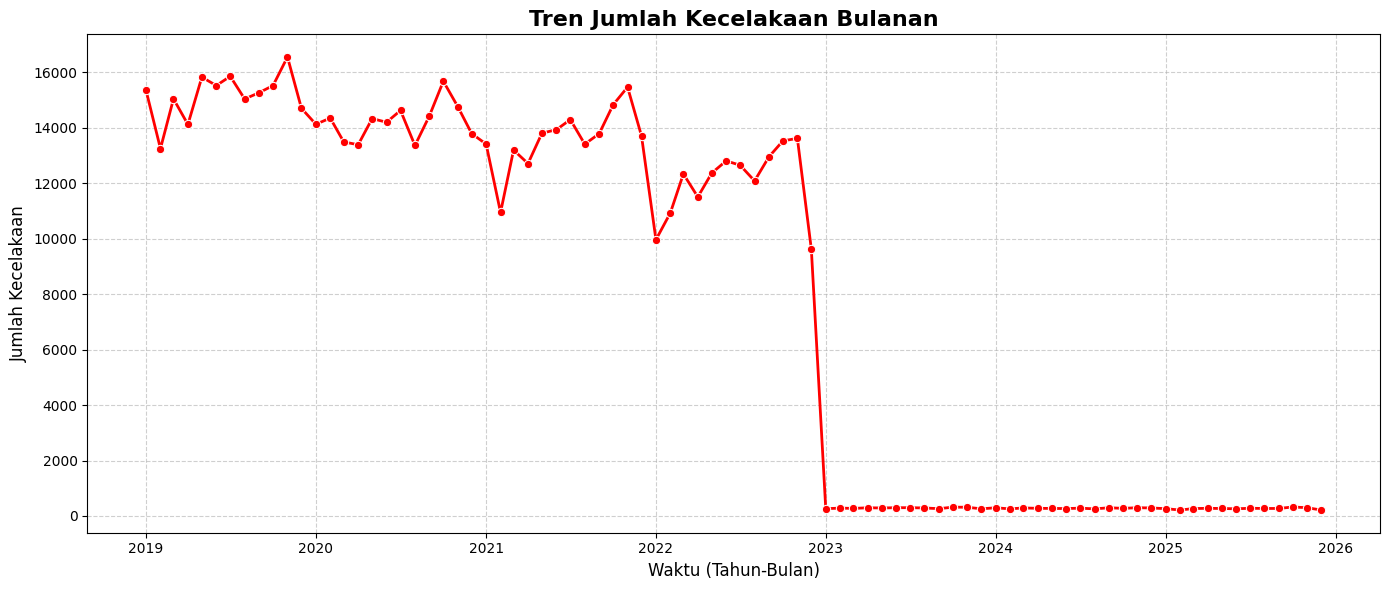

In [14]:
# 1. Mengubah format kolom 'Accident Date' menjadi datetime
df['Accident Date'] = pd.to_datetime(df['Accident Date'], format='%d-%m-%Y', errors='coerce')

# 2. Mengelompokkan data berdasarkan tahun dan bulan untuk melihat tren bulanan
trend_data = df.groupby(df['Accident Date'].dt.to_period('M')).size().reset_index(name='Jumlah Kecelakaan')
trend_data['Accident Date'] = trend_data['Accident Date'].dt.to_timestamp()

# 3. Membuat visualisasi grafik tren kecelakaan
plt.figure(figsize=(14, 6))
sns.lineplot(data=trend_data, x='Accident Date', y='Jumlah Kecelakaan', marker='o', color='red', linewidth=2)
plt.title('Tren Jumlah Kecelakaan Bulanan', fontsize=16, fontweight='bold')
plt.xlabel('Waktu (Tahun-Bulan)', fontsize=12)
plt.ylabel('Jumlah Kecelakaan', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

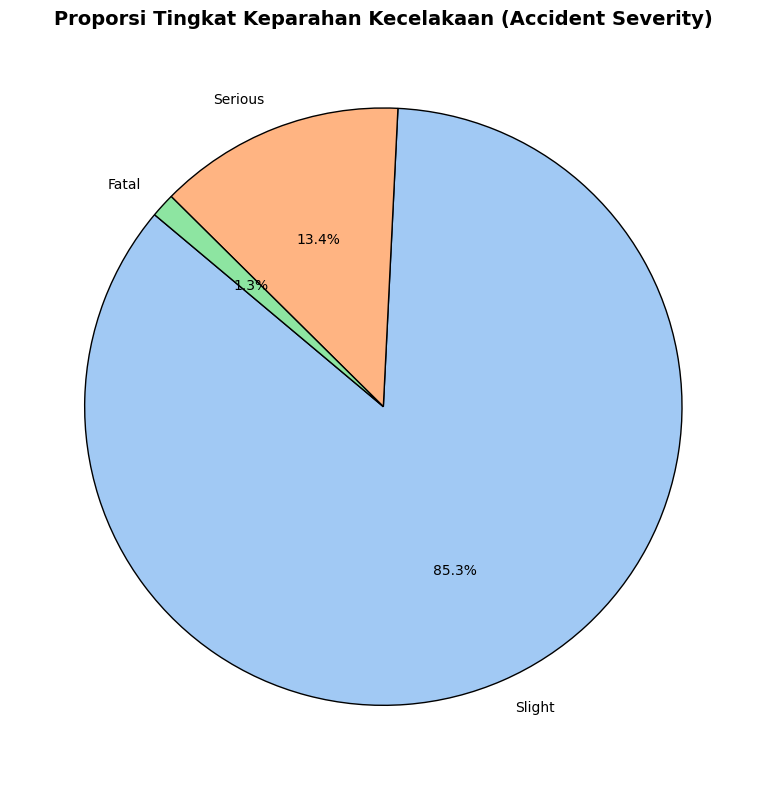

In [15]:
# 1. Menghitung frekuensi tingkat keparahan kecelakaan
severity_counts = df['Accident_Severity'].value_counts()

# 2. Membuat diagram lingkaran (pie chart)
plt.figure(figsize=(8, 8))
plt.pie(
    severity_counts,
    labels=severity_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('pastel')[0:len(severity_counts)],
    wedgeprops={'edgecolor': 'black', 'linewidth': 1, 'antialiased': True}
)
plt.title('Proporsi Tingkat Keparahan Kecelakaan (Accident Severity)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### Insight dari Distribusi Tingkat Keparahan Kecelakaan (*Accident Severity*)

Berdasarkan diagram lingkaran di atas, kita dapat menarik beberapa kesimpulan penting mengenai tingkat keparahan kecelakaan yang tercatat di dalam dataset:

1. **Dominasi Kasus Ringan (*Slight*):**
   Mayoritas sangat besar dari insiden kecelakaan masuk ke dalam kategori **Slight** (Ringan), yaitu mencapai **85.3%** dari total kasus (sebanyak **572,307** insiden). Hal ini menunjukkan bahwa sebagian besar kecelakaan lalu lintas yang terjadi tidak mengakibatkan cedera fatal atau kerusakan yang sangat parah.

2. **Kecelakaan Serius (*Serious*):**
   Kategori **Serious** (Serius) menempati porsi terbesar kedua dengan **13.4%** (sebanyak **89,568** insiden). Meskipun jauh lebih kecil dibanding kategori ringan, angka ini tetap cukup signifikan dan memerlukan perhatian khusus dari segi keselamatan infrastruktur jalan raya.

3. **Kecelakaan Fatal (*Fatal*):**
   Kategori **Fatal** memiliki proporsi terkecil sebesar **1.3%** (sebanyak **8,804** insiden). Walaupun persentasenya kecil, setiap kejadian fatal mewakili hilangnya nyawa manusia, sehingga analisis lebih lanjut mengenai faktor penyebab kecelakaan fatal (seperti kondisi cuaca, tipe kendaraan, atau jenis jalan) sangat penting dilakukan untuk meminimalkan angka ini.

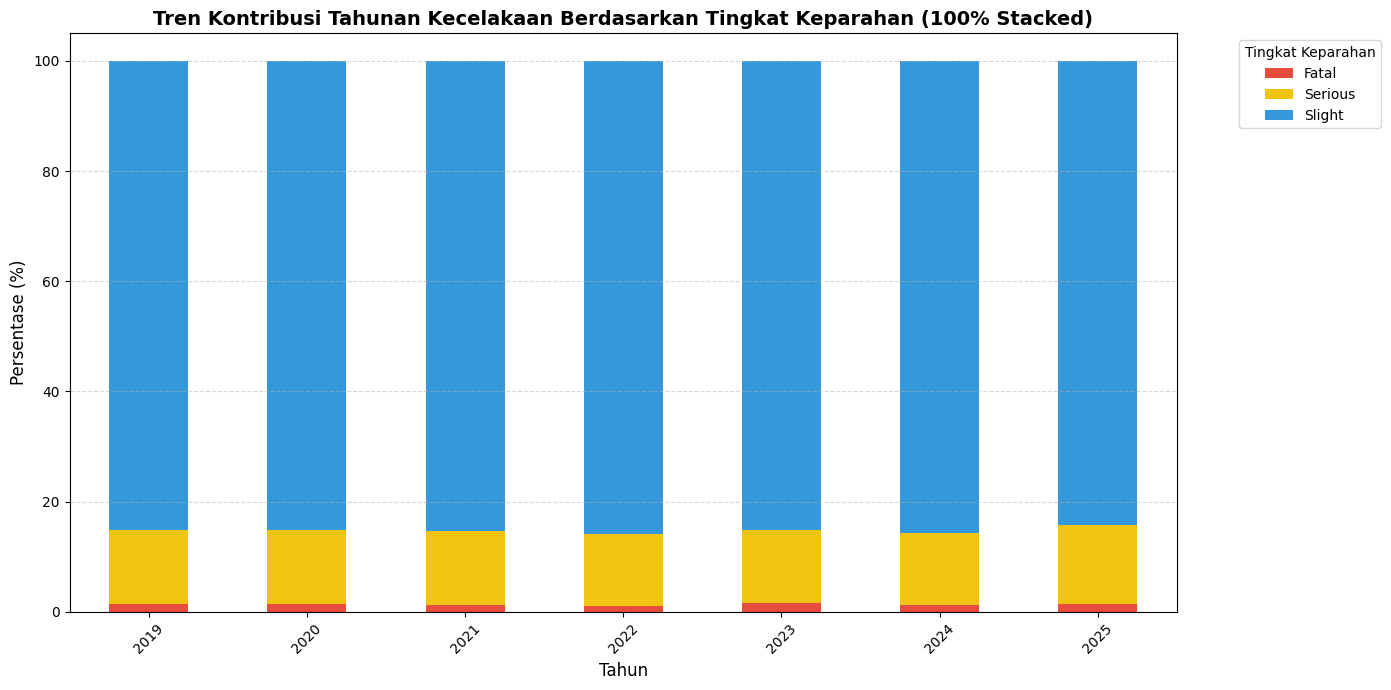

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Ekstrak tahun dari 'Accident Date' jika belum ada
df['Year'] = df['Accident Date'].dt.year

# 2. Mengelompokkan data berdasarkan Tahun dan Accident_Severity, lalu melakukan pivot
severity_trend = df.groupby(['Year', 'Accident_Severity']).size().unstack(fill_value=0)

# 3. Normalisasi data menjadi persentase (100% stacked)
severity_trend_percentage = severity_trend.div(severity_trend.sum(axis=1), axis=0) * 100

# 4. Membuat visualisasi diagram batang bertumpuk 100% (100% stacked bar chart)
severity_trend_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7),
    color=['#e74c3c', '#f1c40f', '#3498db']
)

plt.title('Tren Kontribusi Tahunan Kecelakaan Berdasarkan Tingkat Keparahan (100% Stacked)', fontsize=14, fontweight='bold')
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Persentase (%)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Tingkat Keparahan', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Analisis Hubungan: *Accident Severity* vs *Weather Conditions*

Di bawah ini kita akan menganalisis apakah kondisi cuaca memengaruhi tingkat keparahan kecelakaan menggunakan metode statistik (Uji *Chi-Square*) dan memvisualisasikan proporsinya.

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Membuat tabel kontingensi (cross-tabulation)
cross_tab = pd.crosstab(df['Weather_Conditions'], df['Accident_Severity'])

# 2. Menjalankan Uji Chi-Square
chi2, p_value, dof, expected = chi2_contingency(cross_tab)

print("=== Hasil Uji Chi-Square ===")
print(f"Chi-Square Statistic : {chi2:.4f}")
print(f"p-value             : {p_value}")
print(f"Degrees of Freedom  : {dof}")

if p_value < 0.05:
    print("\nKesimpulan: Ada hubungan statistik yang signifikan antara Kondisi Cuaca dan Tingkat Keparahan Kecelakaan (p-value < 0.05).")
else:
    print("\nKesimpulan: Tidak ada hubungan statistik yang signifikan antara Kondisi Cuaca dan Tingkat Keparahan Kecelakaan (p-value >= 0.05).")


=== Hasil Uji Chi-Square ===
Chi-Square Statistic : 990.6422
p-value             : 1.1291007844320688e-200
Degrees of Freedom  : 16

Kesimpulan: Ada hubungan statistik yang signifikan antara Kondisi Cuaca dan Tingkat Keparahan Kecelakaan (p-value < 0.05).


### Analisis Hubungan: *Accident Severity* vs *Light Conditions*

Di bawah ini kita akan melakukan uji statistik Chi-Square serta memvisualisasikan proporsi tingkat keparahan kecelakaan berdasarkan kondisi pencahayaan saat kejadian (*Light Conditions*).

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Membuat tabel kontingensi (cross-tabulation) antara Light_Conditions dan Accident_Severity
light_cross_tab = pd.crosstab(df['Light_Conditions'], df['Accident_Severity'])

# 2. Menjalankan Uji Chi-Square
chi2_light, p_val_light, dof_light, expected_light = chi2_contingency(light_cross_tab)

print("=== Hasil Uji Chi-Square (Light Conditions vs Accident Severity) ===")
print(f"Chi-Square Statistic : {chi2_light:.4f}")
print(f"p-value             : {p_val_light}")
print(f"Degrees of Freedom  : {dof_light}")

if p_val_light < 0.05:
    print("\nKesimpulan: Ada hubungan statistik yang signifikan antara Kondisi Cahaya (Light Conditions) dan Tingkat Keparahan Kecelakaan (p-value < 0.05).")
else:
    print("\nKesimpulan: Tidak ada hubungan statistik yang signifikan antara Kondisi Cahaya (Light Conditions) dan Tingkat Keparahan Kecelakaan (p-value >= 0.05).")



=== Hasil Uji Chi-Square (Light Conditions vs Accident Severity) ===
Chi-Square Statistic : 4776.9558
p-value             : 0.0
Degrees of Freedom  : 8

Kesimpulan: Ada hubungan statistik yang signifikan antara Kondisi Cahaya (Light Conditions) dan Tingkat Keparahan Kecelakaan (p-value < 0.05).


### Analisis Hubungan: *Accident Severity* vs *Road Surface Conditions*

Di bawah ini kita akan melakukan uji statistik Chi-Square serta memvisualisasikan proporsi tingkat keparahan kecelakaan berdasarkan kondisi permukaan jalan (*Road Surface Conditions*) saat insiden terjadi.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

# 1. Membuat tabel kontingensi (cross-tabulation) antara Road_Surface_Conditions dan Accident_Severity
surface_cross_tab = pd.crosstab(df['Road_Surface_Conditions'], df['Accident_Severity'])

# 2. Menjalankan Uji Chi-Square
chi2_surf, p_val_surf, dof_surf, expected_surf = chi2_contingency(surface_cross_tab)

print("=== Hasil Uji Chi-Square (Road Surface Conditions vs Accident Severity) ===")
print(f"Chi-Square Statistic : {chi2_surf:.4f}")
print(f"p-value             : {p_val_surf}")
print(f"Degrees of Freedom  : {dof_surf}")

if p_val_surf < 0.05:
    print("\nKesimpulan: Ada hubungan statistik yang signifikan antara Kondisi Permukaan Jalan (Road Surface Conditions) dan Tingkat Keparahan Kecelakaan (p-value < 0.05).")
else:
    print("\nKesimpulan: Tidak ada hubungan statistik yang signifikan antara Kondisi Permukaan Jalan (Road Surface Conditions) dan Tingkat Keparahan Kecelakaan (p-value >= 0.05).")


=== Hasil Uji Chi-Square (Road Surface Conditions vs Accident Severity) ===
Chi-Square Statistic : 376.9553
p-value             : 7.504052709136368e-75
Degrees of Freedom  : 10

Kesimpulan: Ada hubungan statistik yang signifikan antara Kondisi Permukaan Jalan (Road Surface Conditions) dan Tingkat Keparahan Kecelakaan (p-value < 0.05).


### Visualisasi Proporsi *Vehicle Type* (Jenis Kendaraan)

Berikut adalah visualisasi kontribusi proporsi jenis kendaraan yang terlibat di dalam kecelakaan.

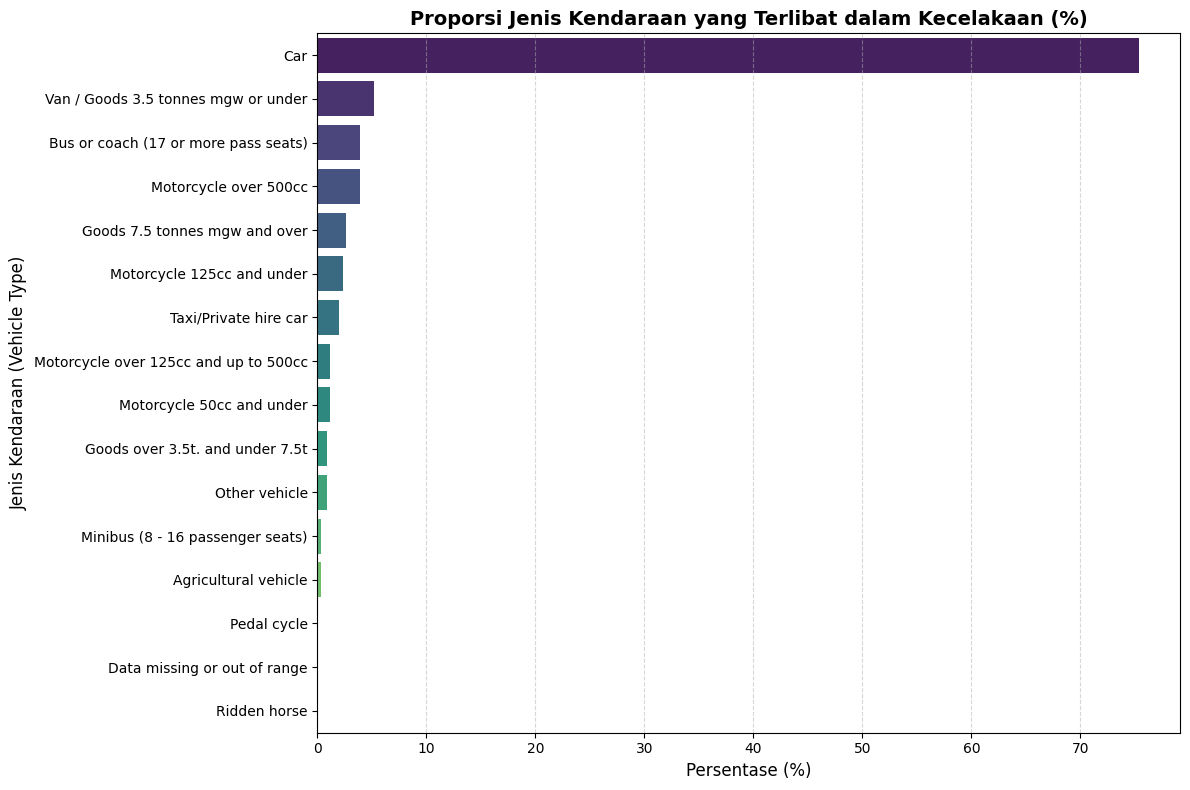

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Menghitung frekuensi dan persentase jenis kendaraan
vehicle_counts = df['Vehicle_Type'].value_counts()
vehicle_percentage = (vehicle_counts / len(df)) * 100

# 2. Membuat DataFrame untuk visualisasi
vehicle_df = pd.DataFrame({
    'Jumlah': vehicle_counts,
    'Persentase (%)': vehicle_percentage
}).reset_index()

# 3. Membuat Plot
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Persentase (%)',
    y='Vehicle_Type',
    data=vehicle_df,
    palette='viridis'
)

plt.title('Proporsi Jenis Kendaraan yang Terlibat dalam Kecelakaan (%)', fontsize=14, fontweight='bold')
plt.xlabel('Persentase (%)', fontsize=12)
plt.ylabel('Jenis Kendaraan (Vehicle Type)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Analisis Tingkat Fatalitas Berdasarkan Jenis Kendaraan (*Vehicle Type*)

Mari kita analisis dan visualisasikan persentase kecelakaan yang berujung fatal untuk setiap jenis kendaraan untuk melihat tipe kendaraan mana yang paling rentan terhadap kecelakaan fatal.

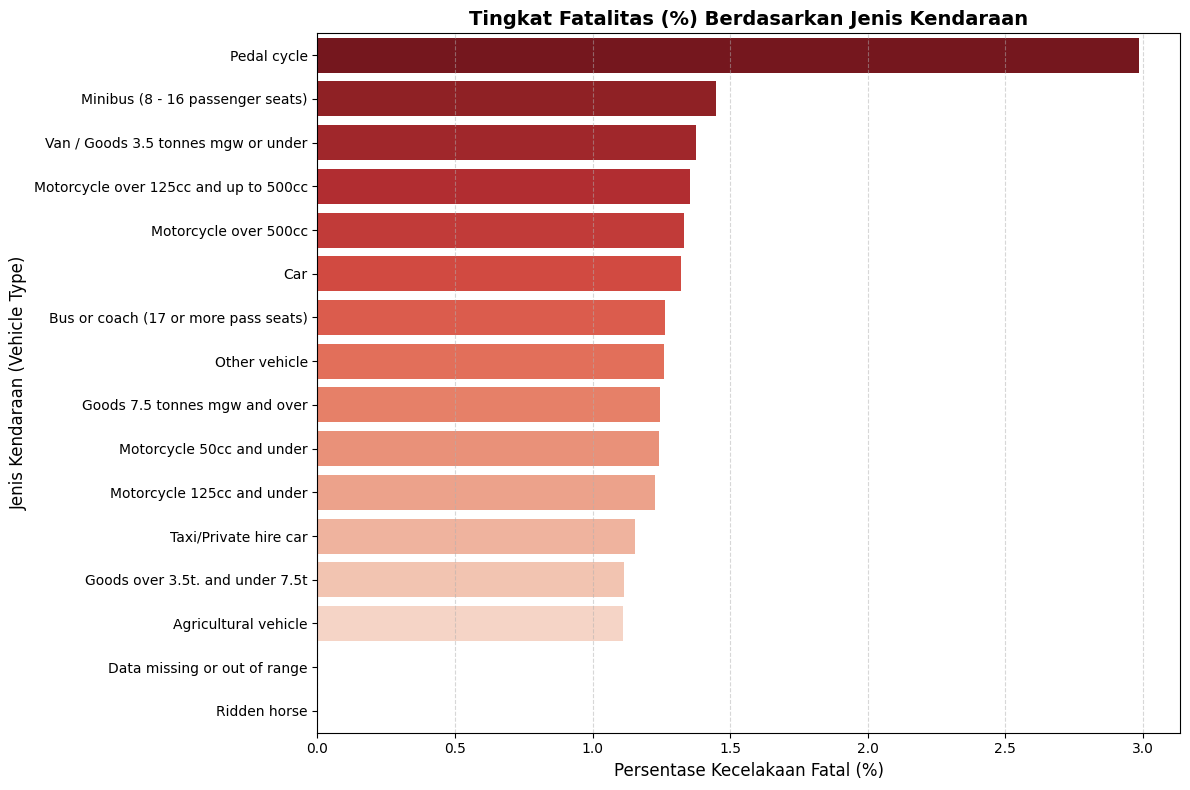

Accident_Severity,Vehicle_Type,Persentase Fatal (%)
0,Pedal cycle,2.985075
1,Minibus (8 - 16 passenger seats),1.447106
2,Van / Goods 3.5 tonnes mgw or under,1.375076
3,Motorcycle over 125cc and up to 500cc,1.352570
4,Motorcycle over 500cc,1.332770
5,Car,1.322250
6,Bus or coach (17 or more pass seats),1.263366
7,Other vehicle,1.260063
8,Goods 7.5 tonnes mgw and over,1.245805
9,Motorcycle 50cc and under,1.241112


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Membuat cross-tabulation antara Vehicle_Type dan Accident_Severity
vehicle_severity_tab = pd.crosstab(df['Vehicle_Type'], df['Accident_Severity'])

# 2. Menghitung persentase tingkat keparahan untuk masing-masing jenis kendaraan
vehicle_severity_pct = vehicle_severity_tab.div(vehicle_severity_tab.sum(axis=1), axis=0) * 100

# 3. Mengurutkan berdasarkan persentase kecelakaan fatal ('Fatal') dari tertinggi ke terendah
vehicle_fatal_rates = vehicle_severity_pct[['Fatal']].sort_values(by='Fatal', ascending=False).reset_index()

# 4. Membuat Plot Visualisasi Tingkat Fatalitas
plt.figure(figsize=(12, 8))
sns.barplot(
    x='Fatal',
    y='Vehicle_Type',
    data=vehicle_fatal_rates,
    palette='Reds_r'
)

plt.title('Tingkat Fatalitas (%) Berdasarkan Jenis Kendaraan', fontsize=14, fontweight='bold')
plt.xlabel('Persentase Kecelakaan Fatal (%)', fontsize=12)
plt.ylabel('Jenis Kendaraan (Vehicle Type)', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

# Menampilkan tabel data agar angka persentase terlihat jelas
display(vehicle_fatal_rates.rename(columns={'Fatal': 'Persentase Fatal (%)'}))

### Analisis Konsentrasi Kecelakaan dan Korban Jiwa Berdasarkan Distrik (`District Area`)

Mari kita analisis distrik mana yang memiliki jumlah kecelakaan terbanyak serta jumlah korban jiwa (`Number_of_Casualties`) tertinggi.

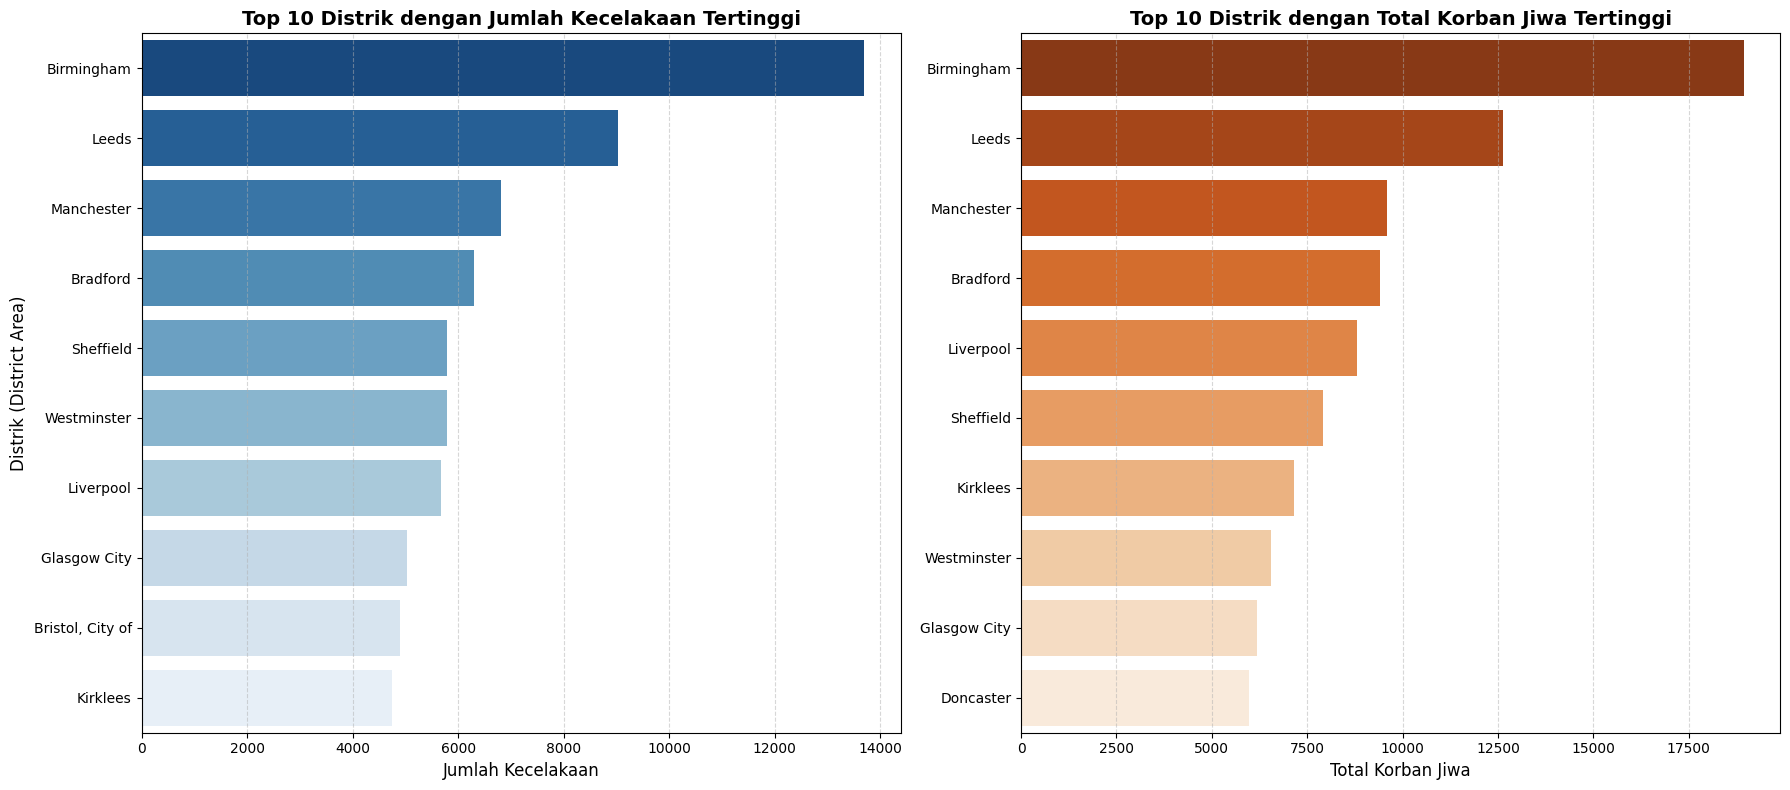

Top 10 Distrik dengan Jumlah Kecelakaan Terbanyak:


,District Area,Jumlah_Kecelakaan,Total_Korban_Jiwa
24,Birmingham,13701,18943
195,Leeds,9027,12632
208,Manchester,6820,9581
36,Bradford,6309,9414
303,Sheffield,5798,7912
404,Westminster,5781,6562
201,Liverpool,5668,8801
147,Glasgow City,5024,6176
44,"Bristol, City of",4894,5954
191,Kirklees,4755,7142



Top 10 Distrik dengan Total Korban Jiwa Terbanyak:


,District Area,Jumlah_Kecelakaan,Total_Korban_Jiwa
24,Birmingham,13701,18943
195,Leeds,9027,12632
208,Manchester,6820,9581
36,Bradford,6309,9414
201,Liverpool,5668,8801
303,Sheffield,5798,7912
191,Kirklees,4755,7142
404,Westminster,5781,6562
147,Glasgow City,5024,6176
105,Doncaster,4136,5977


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Agregasi data berdasarkan District Area
district_analysis = df.groupby('District Area').agg(
    Jumlah_Kecelakaan=('Index', 'count'),
    Total_Korban_Jiwa=('Number_of_Casualties', 'sum')
).reset_index()

# Mengambil top 10 distrik dengan kecelakaan tertinggi
top_10_kecelakaan = district_analysis.sort_values(by='Jumlah_Kecelakaan', ascending=False).head(10)

# Mengambil top 10 distrik dengan korban jiwa tertinggi
top_10_korban = district_analysis.sort_values(by='Total_Korban_Jiwa', ascending=False).head(10)

# Membuat visualisasi
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# Plot 1: Top 10 Distrik Berdasarkan Jumlah Kecelakaan
sns.barplot(
    x='Jumlah_Kecelakaan',
    y='District Area',
    data=top_10_kecelakaan,
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('Top 10 Distrik dengan Jumlah Kecelakaan Tertinggi', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Jumlah Kecelakaan', fontsize=12)
axes[0].set_ylabel('Distrik (District Area)', fontsize=12)
axes[0].grid(axis='x', linestyle='--', alpha=0.5)

# Plot 2: Top 10 Distrik Berdasarkan Total Korban Jiwa
sns.barplot(
    x='Total_Korban_Jiwa',
    y='District Area',
    data=top_10_korban,
    ax=axes[1],
    palette='Oranges_r'
)
axes[1].set_title('Top 10 Distrik dengan Total Korban Jiwa Tertinggi', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Total Korban Jiwa', fontsize=12)
axes[1].set_ylabel('', fontsize=12)
axes[1].grid(axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Menampilkan tabel data top 10
print("Top 10 Distrik dengan Jumlah Kecelakaan Terbanyak:")
display(top_10_kecelakaan)

print("\nTop 10 Distrik dengan Total Korban Jiwa Terbanyak:")
display(top_10_korban)